<a href="https://colab.research.google.com/github/Rageel-28/244107020136-Machine-Learning/blob/main/JS07/JS07_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS07 - Klasterisasi
## Lab 1 - Klasterisasi K-Means dengan Dataset Iris

**Tujuan**
1. Memahami konsep klasterisasi dengan K-Means.
2. Membuat model K-Means menggunakan Python (scikit-learn).
3. Mengevaluasi model dengan *Sum of Square Error* (SSE) dan menentukan nilai $k$ terbaik dengan *Elbow Method*.

Dataset Iris sebenarnya sudah memiliki label (`Species`) sehingga bisa dipakai untuk klasifikasi. Pada praktikum ini kita **berasumsi data tidak berlabel** agar relevan untuk klasterisasi.

## Langkah 0 - Download Dataset

Unduh `Iris.csv` dari modul praktikum, lalu letakkan satu folder dengan notebook ini (atau upload ke Google Colab).

Sel di bawah akan memeriksa apakah `Iris.csv` sudah ada. Jika belum ada dan Anda memakai Google Colab, akan muncul dialog upload. Jika tetap tidak ada, dataset Iris dari `scikit-learn` dipakai sebagai cadangan dengan nama kolom yang sama persis dengan `Iris.csv` (`Id`, `SepalLengthCm`, `SepalWidthCm`, `PetalLengthCm`, `PetalWidthCm`, `Species`).

In [1]:
import os

if not os.path.exists('Iris.csv'):
    try:
        from google.colab import files
        print('Silakan upload file Iris.csv')
        files.upload()
    except ImportError:
        pass

if os.path.exists('Iris.csv'):
    print('Iris.csv ditemukan.')
else:
    print('Iris.csv tidak ditemukan -> membuat Iris.csv dari dataset Iris scikit-learn sebagai cadangan.')
    from sklearn.datasets import load_iris
    import pandas as pd
    iris = load_iris()
    _df = pd.DataFrame(iris.data, columns=['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm'])
    _df.insert(0, 'Id', range(1, len(_df) + 1))
    _df['Species'] = ['Iris-' + iris.target_names[t] for t in iris.target]
    _df.to_csv('Iris.csv', index=False)

Silakan upload file Iris.csv


Saving iris.csv to iris (1).csv
Iris.csv tidak ditemukan -> membuat Iris.csv dari dataset Iris scikit-learn sebagai cadangan.


## Langkah 1 - Import Library

Import library yang dibutuhkan.

In [2]:
# Import required library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

## Langkah 2 - Load dan Inspeksi Data

Muat data ke dalam *dataframe*, lalu lakukan inspeksi 5 data pertama.

In [3]:
df = pd.read_csv('Iris.csv')
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


Selanjutnya, inspeksi profil data. Seharusnya terdapat 150 data dan tidak ada *missing values* pada seluruh variabel.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


## Langkah 3 - Seleksi Fitur

Karena hanya fitur yang dibutuhkan untuk klasterisasi, pisahkan fitur dan label dengan *slicing*. Indeks `[:, 1:-1]` berarti kolom `Id` (pertama) dan `Species` (terakhir, label) tidak digunakan.

In [5]:
# Features Selection
X = df.iloc[:, 1:-1]  # slice the features
y = df.iloc[:, -1]    # this is the labels (we don't need it)

In [6]:
print(X.head())

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2


## Langkah 4 - Plotting

*Scatter plot* untuk melihat sebaran data berdasarkan 2 fitur, yaitu `SepalLengthCm` dan `SepalWidthCm`.

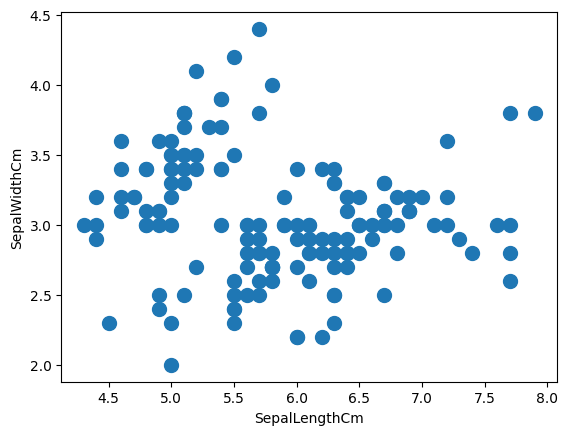

In [7]:
# Make a scatterplot using
# SepalLengthCm and SepalWidthCm
plt.xlabel('SepalLengthCm')
plt.ylabel('SepalWidthCm')
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100)
plt.show()

Secara visual, kita mungkin dapat berasumsi bahwa terdapat **dua *cluster*** pada data.

## Langkah 5 - Membuat Model K-Means

Buat model K-Means dengan asumsi terdapat dua *cluster* sesuai amatan visual pada *scatter plot*.

> Titik centroid awal ditentukan secara acak, sehingga hasil bisa berbeda tiap dijalankan. Di sini `random_state` diberi nilai agar hasil dapat direproduksi.

In [8]:
# Build a K-Means Model
# Based on visual inspection using scatterplot,
# we can assume that the data has 2 clusters
# (even though, from the label, there are 3 labels in this data)

from sklearn.cluster import KMeans

# Initiate K-Means object with number of cluster is 2
cl_kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)

# Fit and predict
y_kmeans = cl_kmeans.fit_predict(X)

Cek hasil klasterisasi dengan *scatter plot*, lengkap dengan titik centroid (merah).

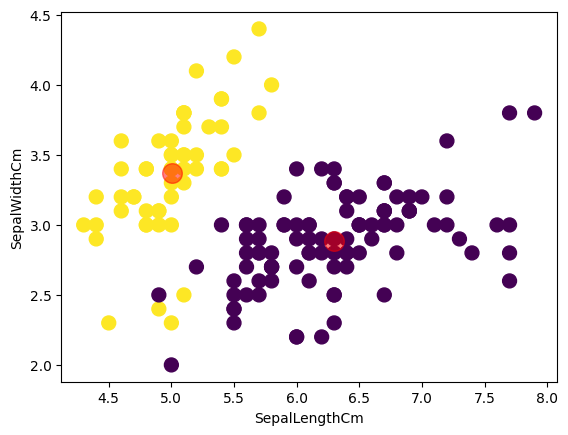

In [9]:
# Plot the clustering result
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100, c=y_kmeans)

# Plot the centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)
plt.xlabel('SepalLengthCm')
plt.ylabel('SepalWidthCm')
plt.show()

## Langkah 6 - Evaluasi Model

Salah satu metrik evaluasi adalah ***Sum of Square Error* (SSE)**. Nilainya didapat dari properti `inertia_` pada objek K-Means yang telah dilatih.

In [10]:
# Print SSE value
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 152.34795176035797


> **NB:** Nilai Anda bisa berbeda dari contoh modul (≈ 152.37) karena titik centroid awal ditentukan secara acak.

## Langkah 7 - Menentukan $k$ Terbaik dengan Elbow Method

Jika jumlah *cluster* belum ditentukan, gunakan *elbow method*:
1. Tentukan rentang $k$ yang ingin dievaluasi.
2. Hitung nilai SSE untuk setiap $k$ pada rentang tersebut.
3. Buat *line plot* sebagai dasar justifikasi.

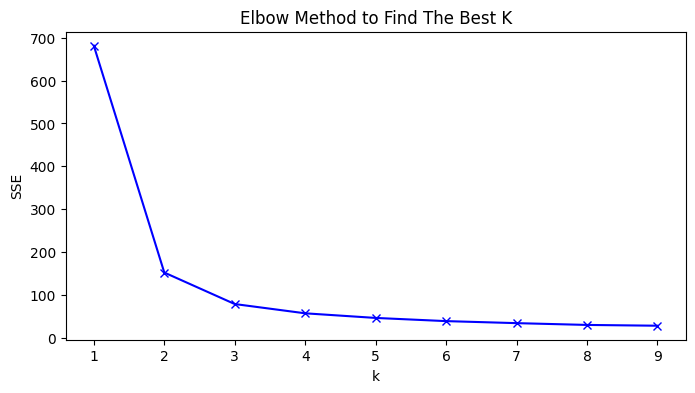

In [11]:
# Find the best k
# using Elbow Method

# List SSE values
sse = []

# Build k range from 1 to 9
K = range(1, 10)

# Find the SSE value for each k
for k in K:
    kmeanModel = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

# Plotting the distortions
plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Elbow Method to Find The Best K")
plt.show()

In [12]:
# Nilai SSE tiap k dan penurunannya dari k sebelumnya
for k, s in zip(K, sse):
    sebelumnya = sse[k - 2] if k > 1 else None
    turun = f'{sebelumnya - s:.2f}' if sebelumnya is not None else '-'
    print(f'k = {k} | SSE = {s:8.2f} | penurunan = {turun}')

k = 1 | SSE =   681.37 | penurunan = -
k = 2 | SSE =   152.35 | penurunan = 529.02
k = 3 | SSE =    78.85 | penurunan = 73.50
k = 4 | SSE =    57.23 | penurunan = 21.62
k = 5 | SSE =    46.46 | penurunan = 10.77
k = 6 | SSE =    39.04 | penurunan = 7.42
k = 7 | SSE =    34.31 | penurunan = 4.73
k = 8 | SSE =    30.13 | penurunan = 4.17
k = 9 | SSE =    28.29 | penurunan = 1.84


### Analisis

Berdasarkan *line plot* SSE untuk setiap $k$, nilai $k$ terbaik adalah **3**.

- Pada $k=2$ nilai SSE masih terlalu tinggi dibandingkan $k=3$ dan $k=4$.
- Setelah $k=3$, penurunan SSE menjadi landai dan stabil (posisi "siku" / *elbow*).
- **Jumlah *cluster* terbaik bukan karena nilai SSE yang paling rendah.** SSE pasti mengecil seiring bertambahnya jumlah *cluster*, karena anggota tiap *cluster* makin sedikit dan wilayahnya makin sempit. Yang dicari adalah posisi di mana SSE turun tajam lalu diikuti penurunan yang lebih stabil.

Hal ini sejalan dengan label asli dataset Iris yang memiliki 3 spesies.

## Tambahan - Cross-check dengan Silhouette Coefficient

*Elbow method* hanya melihat *intra cluster* (SSE). Sebagai pembanding, *silhouette score* mempertimbangkan *intra* dan *inter cluster* (rentang −1 hingga +1, makin dekat +1 makin baik).

In [13]:
from sklearn.metrics import silhouette_score

for k in range(2, 10):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    print(f'k = {k} | silhouette = {silhouette_score(X, labels):.4f}')

k = 2 | silhouette = 0.6810
k = 3 | silhouette = 0.5528
k = 4 | silhouette = 0.4981
k = 5 | silhouette = 0.4912
k = 6 | silhouette = 0.3648
k = 7 | silhouette = 0.3543
k = 8 | silhouette = 0.3487
k = 9 | silhouette = 0.3125
